# 03 · The Quantitative Comparative Approach (paper Tables 3–5)

> **Paper** &nbsp; I-Cheng Yeh and Tzu-Kuang Hsu (2018), "Building real estate
> valuation models with comparative approach through case-based reasoning",
> *Applied Soft Computing* **65**, 260-271.
> [doi:10.1016/j.asoc.2018.01.029](https://doi.org/10.1016/j.asoc.2018.01.029)
>
> **Data** &nbsp; UCI Machine Learning Repository, *Real Estate Valuation*
> ([doi:10.24432/C5J30W](https://doi.org/10.24432/C5J30W)), CC BY 4.0 — the
> Sindian circle of supply and demand, 414 transactions.

---

## The method in four steps

For a target property, against every comparative case $j$ in the same circle:

1. **Distance** (Eq. 32) — a weighted, standardised Euclidean distance over the appraisal factors.
2. **Weight** (Eq. 33) — $F_j = \exp[-(D_j/\delta)^2]$, a Gaussian kernel of *effect radius* $\delta$.
3. **Adjustment** (Eq. 34) — the comparative case's real transaction price, corrected factor by factor by $K_i = \hat{k}_i(\text{target})/\hat{k}_i(\text{comparative})$.
4. **Weighted average** (Eq. 35) — $\hat{Y} = \sum_j F_jY_j / \sum_j F_j$.

Steps 1–2 are ordinary kernel regression. **Step 3 is the contribution.** A hedonic regression returns a number; this returns a number *plus the real trades it came from and the priced reason for every difference*. That is what the paper argues appraisers need to persuade a client, and it is what the traditional comparative approach does by subjective judgement.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qca import config, data, experiments, importance, metrics, plots
from qca.decomposition import StepwiseDecomposition
from qca.estimator import QuantitativeComparativeApproach
from qca.benchmarks import MultivariateRegression, PaperMLP

plots.use_paper_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
df = data.load()
train, test = data.train_test_split_paper(df, config.RANDOM_STATE)
mean_price = float(df[config.TARGET].mean())

## 1. Weights of the characteristic variables (paper Table 3)

Four schemes. Methods 1 and 2 make the weight proportional to the root of the Eq. (8) variance and to the variance itself. Methods 3 and 4 are the same two rules averaged over **all four** circles of supply and demand.

Only Sindian was released with the paper, so methods 3 and 4 cannot be recomputed from this data. Rather than silently substitute something else, the project passes the **values printed in Table 3** and says so; `characteristic_weights` raises if they are not supplied. The weight of the geographic coordinate cannot be scored this way either, and the paper fixes it at 3.

In [3]:
weights = importance.weights_table(
    train,
    experiments.POOLED_WEIGHTS_METHOD3,
    experiments.POOLED_WEIGHTS_METHOD4,
)
weights

,Distance to the nearest MRT station,Number of convenience stores in the living circle on foot,House age,Transaction date
Method 1,2.8928,2.3573,1.7061,1.0000
Method 2,8.3681,5.5569,2.9108,1.0000
Method 3,2.8000,2.4000,2.4000,1.0000
Method 4,9.1000,6.2000,6.4000,1.0000


In [4]:
paper_t3 = pd.DataFrame(
    [[3.7, 2.9, 2.3, 1.0], [13.4, 8.2, 5.5, 1.0],
     [2.8, 2.4, 2.4, 1.0], [9.1, 6.2, 6.4, 1.0]],
    index=weights.index, columns=weights.columns,
)
print("ratio of each weight to the house-age weight "
      "(removes the noisy transaction-date denominator):")
ours = weights.iloc[0] / weights.iloc[0, 2]
theirs = paper_t3.iloc[0] / paper_t3.iloc[0, 2]
pd.DataFrame({"ours (method 1)": ours, "paper (method 1)": theirs}).round(3)

ratio of each weight to the house-age weight (removes the noisy transaction-date denominator):


,ours (method 1),paper (method 1)
Distance to the nearest MRT station,1.6960,1.6090
Number of convenience stores in the living circle on foot,1.3820,1.2610
House age,1.0000,1.0000
Transaction date,0.5860,0.4350


Scaled against house age instead of the transaction date the two agree closely. The weights are the same object; the published normaliser is simply the noisiest of the four.

## 2. The case distance and the effect radius

Two implementation choices have to be made explicit, because the paper's text leaves them open.

**The square root.** Equation (32) is printed as a ratio of sums. Taken literally it is a squared distance; the kernel of Eq. (33) then squares it again. This project takes the root, so $D$ is a distance in standard-deviation units and the paper's own description of the kernel holds — weight $1$ at $D=0$, $1/e \approx 0.368$ at $D=\delta$.

**The coordinates.** The geographic coordinate is one factor with two components. Each of northing and easting enters the sum carrying the factor's weight of 3.

In [5]:
model = QuantitativeComparativeApproach(
    weights=experiments.weights_for(train, 1), effect_radius=1.5
).fit(train)

pred, detail = model.predict(test, return_detail=True)
D = detail["distance"]
print(f"case distance  min {D.min():.3f}  median {np.median(D):.3f}  max {D.max():.3f}")
print(f"case weight    min {detail['weight'].min():.3f}  "
      f"median {np.median(detail['weight']):.3f}  max {detail['weight'].max():.3f}")

case distance  min 0.000  median 1.188  max 3.523
case weight    min 0.004  median 0.534  max 1.000


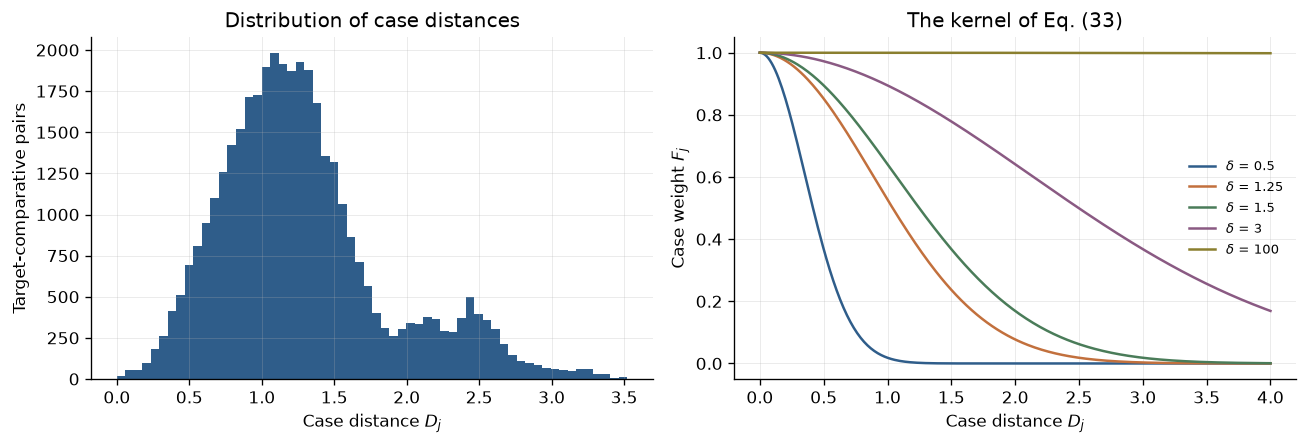

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(D.ravel(), bins=60, color=plots.PALETTE[0])
axes[0].set_xlabel("Case distance $D_j$")
axes[0].set_ylabel("Target-comparative pairs")
axes[0].set_title("Distribution of case distances")

grid = np.linspace(0, 4, 300)
for radius in [0.5, 1.25, 1.5, 3.0, 100.0]:
    axes[1].plot(grid, np.exp(-((grid / radius) ** 2)),
                 label=f"$\\delta$ = {radius:g}")
axes[1].set_xlabel("Case distance $D_j$")
axes[1].set_ylabel("Case weight $F_j$")
axes[1].set_title("The kernel of Eq. (33)")
axes[1].legend(fontsize=8)
fig.tight_layout()

Median distance is near 1, so radii of 1.25–3 — the paper's search range — do discriminate between near and far comparatives, while $\delta = 100$ flattens the kernel to a simple average. The two extremes the paper warns about are both inside the grid.

## 3. The RMSE grid (paper Table 4)

In [7]:
grid_table = experiments.radius_grid(train, test)
grid_table

,100.0000,5.0000,3.0000,2.0000,1.7500,1.5000,1.2500,Min
Method 1,7.3277,7.3272,7.3254,7.3216,7.3197,7.3171,7.3131,7.3131
Method 2,7.3277,7.3270,7.3241,7.3173,7.3140,7.3097,7.3037,7.3037
Method 3,7.3277,7.3271,7.3253,7.3213,7.3192,7.3163,7.3116,7.3116
Method 4,7.3277,7.3268,7.3238,7.3167,7.3130,7.3080,7.3010,7.3010


In [8]:
paper_t4 = pd.DataFrame(
    [[7.98, 7.95, 7.77, 7.68, 7.78, 7.80, 7.82],
     [7.98, 7.83, 7.80, 8.23, 8.30, 8.35, 8.45],
     [7.98, 7.95, 7.81, 7.73, 7.74, 7.82, 7.87],
     [7.98, 7.92, 7.91, 8.12, 8.27, 8.35, 8.39]],
    index=grid_table.index, columns=config.EFFECT_RADII,
)
print("paper Table 4, Sindian:")
paper_t4

paper Table 4, Sindian:


,100.0000,5.0000,3.0000,2.0000,1.7500,1.5000,1.2500
Method 1,7.9800,7.9500,7.7700,7.6800,7.7800,7.8000,7.8200
Method 2,7.9800,7.8300,7.8000,8.2300,8.3000,8.3500,8.4500
Method 3,7.9800,7.9500,7.8100,7.7300,7.7400,7.8200,7.8700
Method 4,7.9800,7.9200,7.9100,8.1200,8.2700,8.3500,8.3900


Two differences are worth stating plainly.

**The level is better here** — about 7.3 against the paper's 7.7–8.5. The split differs, so some gap is expected, but the whole grid sits below the published one.

**The grid is far flatter here.** The paper's RMSE moves ~10% across radii; ours moves under 1%. The reason is visible in notebook 02: the decomposition model already predicts the test set at RMSE ≈ 7.33, so once prices are corrected by the coefficient ratios of Eq. (34) the adjusted prices are nearly the same whichever comparative they came from, and reweighting them changes little. A likely cause of the difference is conditioning: the paper fits the Eq. (25) surface on absolute metre coordinates (values near 2,760,000), where the quadratic terms are badly scaled, while this project centres them first. A weaker location model leaves more spatial structure for the kernel to recover, and a steeper radius curve.

The ranking of methods and the shape of the curve are reproduced; the magnitude of the radius effect is not.

Text(0.5, 1.0, 'Test RMSE against the effect radius')

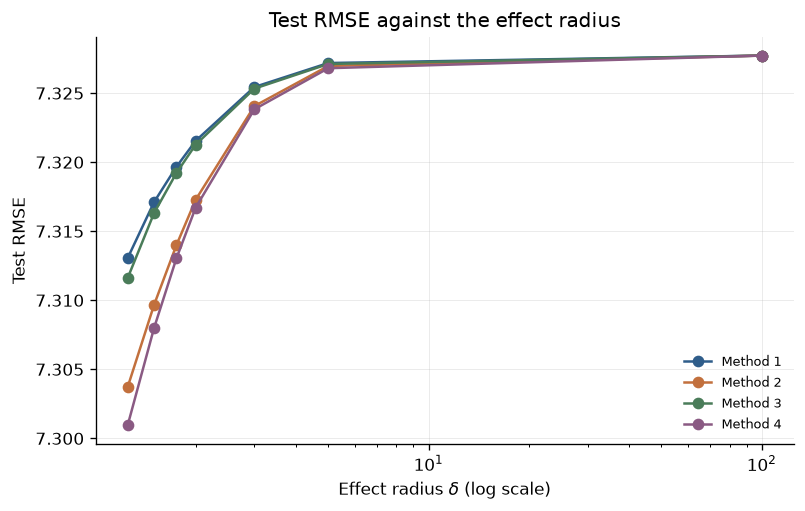

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
plots.radius_curve(grid_table.drop(columns="Min"), ax=ax)
ax.set_title("Test RMSE against the effect radius")

In [10]:
method, radius = experiments.best_setting(grid_table)
print(f"best cell: weighting method {method}, effect radius {radius}")

best cell: weighting method 4, effect radius 1.25


⚠️ **This is the paper's procedure, and it is the paper's weakest step.** The radius and the weighting method are chosen by reading the minimum off a grid scored on the *test* set, so the reported RMSE is not an out-of-sample figure for the chosen configuration. Notebook 05 re-runs the comparison with the radius cross-validated inside the training set, which is the honest version.

## 4. Table 5 of the paper

In [11]:
best = QuantitativeComparativeApproach(
    weights=experiments.weights_for(train, method), effect_radius=radius
).fit(train)
qca_pred = best.predict(test)

table5 = pd.Series(
    metrics.evaluate(test[config.TARGET], qca_pred, mean_price)
).to_frame("replication")
table5["paper (Table 5)"] = [80.2, 52.9, 0.683, np.nan, 7.73,
                             np.nan, np.nan, 37.98, 0.204]
table5.round(4)

,replication,paper (Table 5)
20% error hit rate,76.0870,80.2000
10% error hit rate,53.6232,52.9000
R2 (1-SSE/SST),0.6818,0.6830
R2 (corr^2),0.6916,NaN
RMSE,7.3010,7.7300
MAE,4.9129,NaN
MAPE,16.6957,NaN
Avg. house price,37.9802,37.9800
RMSE/Avg. house price,0.1922,0.2040


### Which $R^2$?

The paper never says. The two usual definitions disagree whenever predictions are biased, and the $R^2$/RMSE pairs printed across Tables 5–7 are only mutually consistent under the squared-correlation reading — the three tables share one test set, yet $1-SSE/SST$ would imply three different test variances for it. Both are reported throughout.

<Axes: title={'center': 'QCA on the test set (paper Fig. 9)'}, xlabel='Actual price per unit area', ylabel='Predicted price per unit area'>

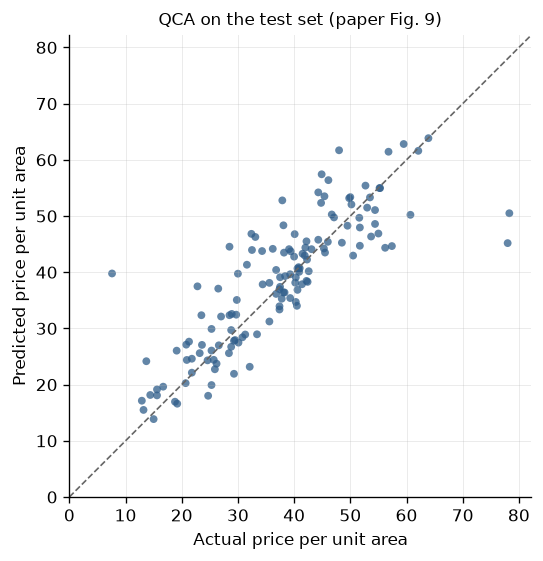

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
plots.actual_vs_predicted(test[config.TARGET], qca_pred, ax=ax,
                          title="QCA on the test set (paper Fig. 9)")

## 5. A worked appraisal — the output that justifies the method

Everything above evaluates the approach as a predictor. This is what it produces *as an appraisal*: the real transactions behind one valuation and the correction applied to each.

In [13]:
target = test.iloc[0]
report = best.comparables(target, k=6)
print("TARGET CASE")
for f in config.DECOMPOSITION_ORDER:
    print(f"  {config.LABELS[f]:<60s} {target[f]:>12,.2f}")
print(f"\n  estimated price  {report.attrs['estimate']:.2f}")
print(f"  actual price     {target[config.TARGET]:.2f}")
print(f"  error            {report.attrs['estimate'] - target[config.TARGET]:+.2f}")
report.round(4)

TARGET CASE
  Distance to the nearest MRT station                                211.45
  Number of convenience stores in the living circle on foot            1.00
  House age                                                           10.30
  Transaction date                                                 2,012.83

  estimated price  44.23
  actual price     45.30
  error            -1.07


,mrt,stores,age,date,price,case distance,case weight,adjusted price,correction factor
101,170.1289,1,12.7000,"2,012.8333",32.9000,0.1024,0.9933,32.1404,0.9769
399,170.1289,1,12.7000,"2,012.9167",37.3000,0.1162,0.9914,35.7230,0.9577
256,339.2289,1,14.6000,"2,012.6667",26.5000,0.2216,0.9691,30.6060,1.1549
17,350.8515,1,17.7000,"2,012.7500",37.4000,0.3218,0.9359,42.9590,1.1486
270,252.5822,1,10.8000,"2,013.3333",117.5000,0.3315,0.9321,108.3483,0.9221
238,732.8528,0,12.8000,"2,013.0833",40.6000,0.3636,0.9189,49.4824,1.2188


Read one row. A comparative case that traded at 32.9 but is slightly less well located carries a correction factor near 0.98, so it contributes an adjusted 32.1 — and it contributes heavily, because its case distance is 0.10. That is an appraisal a client can be walked through, which is precisely the advantage the paper claims over a hedonic regression.

It also shows the method's exposure. The 117.5 outlier identified in notebook 01 appears among the nearest comparatives for some targets; because Eq. (35) is a weighted mean rather than a weighted median, a single anomalous trade moves the estimate.

In [14]:
_, best_detail = best.predict(test, return_detail=True)
contrib = pd.DataFrame({
    "case weight": best_detail["weight"][0],
    "adjusted price": best_detail["adjusted"][0],
})
contrib["share of the estimate"] = (
    contrib["case weight"] / contrib["case weight"].sum()
)
top = contrib.sort_values("share of the estimate", ascending=False)
print(f"comparatives carrying half the weight: "
      f"{int((top['share of the estimate'].cumsum() <= 0.5).sum()) + 1}"
      f" of {len(top)}")
print(f"largest single share: {top['share of the estimate'].iloc[0]:.1%}")

comparatives carrying half the weight: 91 of 276
largest single share: 0.8%


## 6. Does the comparison step earn its keep?

Against the plain decomposition model of notebook 02:

In [15]:
pd.DataFrame({
    "decomposition model only":
        metrics.evaluate(test[config.TARGET],
                         best.decomposition.predict_price(test), mean_price),
    "full QCA":
        metrics.evaluate(test[config.TARGET], qca_pred, mean_price),
}).T.round(4)

,20% error hit rate,10% error hit rate,R2 (1-SSE/SST),R2 (corr^2),RMSE,MAE,MAPE,Avg. house price,RMSE/Avg. house price
decomposition model only,76.0870,52.8986,0.6792,0.6920,7.3312,4.9643,16.7898,37.9802,0.1930
full QCA,76.0870,53.6232,0.6818,0.6916,7.3010,4.9129,16.6957,37.9802,0.1922


On this split the gain in RMSE is small. The case for the approach rests less on accuracy than on the auditable output shown in section 5 — which is, in fairness, the argument the paper itself makes in its Table 8.